# Detecção de Anomalias Não Supervisionada em Séries Temporais

**Objetivo:** Aplicar, comparar e combinar diferentes paradigmas de **Aprendizado de Máquina Não Supervisionado** para identificar comportamentos anômalos em dados de sensores IoT (temperatura ambiente interna com registro de falha no sistema de climatização).

**Dataset:** `ambient_temperature_system_failure.csv` proveniente do *Numenta Anomaly Benchmark (NAB)*.

### Abordagens Avaliadas:
1. **Clusterização (K-Means + PCA):** Identificação de anomalias por distância euclidiana aos centroides.
2. **Distribuição Estatística (Elliptic Envelope):** Modelagem Gaussiana segmentada por contexto temporal.
3. **Isolamento Baseado em Árvores (Isolation Forest):** Particionamento recursivo aleatório.
4. **Fronteira de Decisão Não Linear (One-Class SVM):** Delimitação de hiperplano de normalidade.
5. **Deep Learning Sequencial (LSTM):** Previsão temporal e detecção baseada em erro residual.

Ao final, os resultados são **validados** contra as janelas de falha rotuladas pelo próprio NAB (`labels/combined_windows.json`). Esses rótulos **não** são usados no treinamento de nenhum modelo.

## 1. Configuração do Ambiente e Coleta de Dados

Nesta etapa inicial, realizamos o **download direto** do conjunto de dados a partir do repositório oficial do NAB e importamos as bibliotecas essenciais para:
* **Manipulação tabular e numérica:** `pandas` e `numpy`
* **Visualização de dados:** `matplotlib` e `seaborn`
* **Pré-processamento e modelagem:** `scikit-learn`

In [1]:
!wget -q https://raw.githubusercontent.com/numenta/NAB/master/data/realKnownCause/ambient_temperature_system_failure.csv

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

# Configuração visual padrão dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
print("Ambiente preparado e dataset carregado com sucesso.")

Ambiente preparado e dataset carregado com sucesso.


## 2. Pré-processamento e Engenharia de Atributos (*Feature Engineering*)

Em séries temporais de ambientes corporativos, a definição de "normalidade" depende diretamente do **contexto temporal** (horário comercial *versus* madrugada, dias úteis *versus* fins de semana). Para permitir que os algoritmos capturem essa sazonalidade, executamos as seguintes transformações:

* **Padronização de unidade:** Conversão da temperatura de Fahrenheit para Celsius ($^\circ\text{C}$).
* **Extração temporal:** Criação das variáveis `hours` (hora do dia), `daylight` (período ativo entre 07h e 22h), `DayOfTheWeek` (dia da semana) e `WeekDay` (indicador binário de dia útil).
* **Categorização contextual:** Combinação de dia útil e período do dia em **4 regimes operacionais distintos** (`categories`).
* **Taxa de contaminação (`outliers_fraction`):** Definida em **`0.01` (1%)**, assumindo que anomalias representam eventos raros na série.

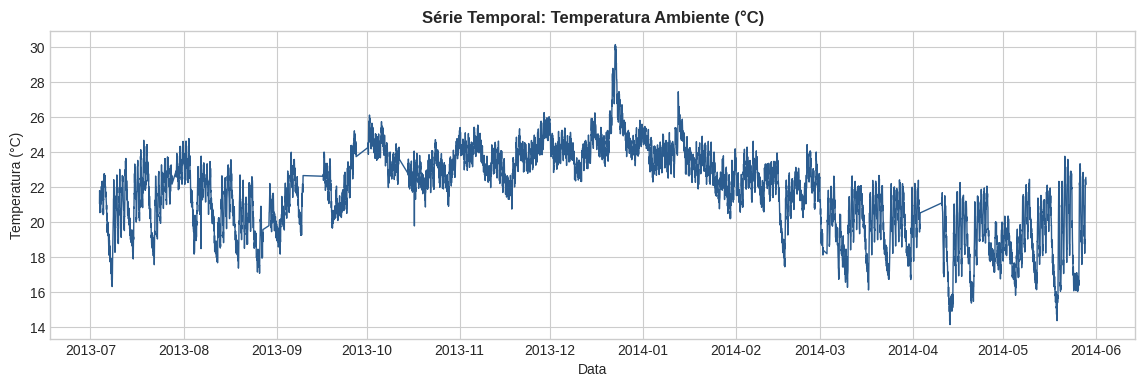

,timestamp,value,hours,daylight,DayOfTheWeek,WeekDay,categories
0,2013-07-04 00:00:00,21.044908,0,0,3,1,2
1,2013-07-04 01:00:00,21.789015,1,0,3,1,2
2,2013-07-04 02:00:00,21.598781,2,0,3,1,2
3,2013-07-04 03:00:00,20.533000,3,0,3,1,2
4,2013-07-04 04:00:00,20.713084,4,0,3,1,2


In [2]:
df = pd.read_csv("ambient_temperature_system_failure.csv")

# Conversão de data e temperatura (Fahrenheit -> Celsius)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['value'] = (df['value'] - 32) * 5/9

# Criação de atributos temporais
df['hours'] = df['timestamp'].dt.hour
df['daylight'] = ((df['hours'] >= 7) & (df['hours'] <= 22)).astype(int)
df['DayOfTheWeek'] = df['timestamp'].dt.dayofweek
df['WeekDay'] = (df['DayOfTheWeek'] < 5).astype(int)

# Criação das 4 categorias de regime operacional
df['categories'] = df['WeekDay']*2 + df['daylight']

# Parâmetro global da proporção esperada de anomalias
outliers_fraction = 0.01

# Visualização da série temporal completa
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', linewidth=1)
ax.set_title("Série Temporal: Temperatura Ambiente (°C)", fontsize=12, fontweight='bold')
ax.set_xlabel("Data")
ax.set_ylabel("Temperatura (°C)")
plt.show()

df.head()

### 2.1 Análise Exploratória por Regime Operacional

Para verificar se a separação em 4 categorias faz sentido, comparamos a distribuição da temperatura em cada regime. Se as distribuições forem diferentes, isso confirma que uma mesma temperatura pode ser normal em um contexto e anômala em outro.

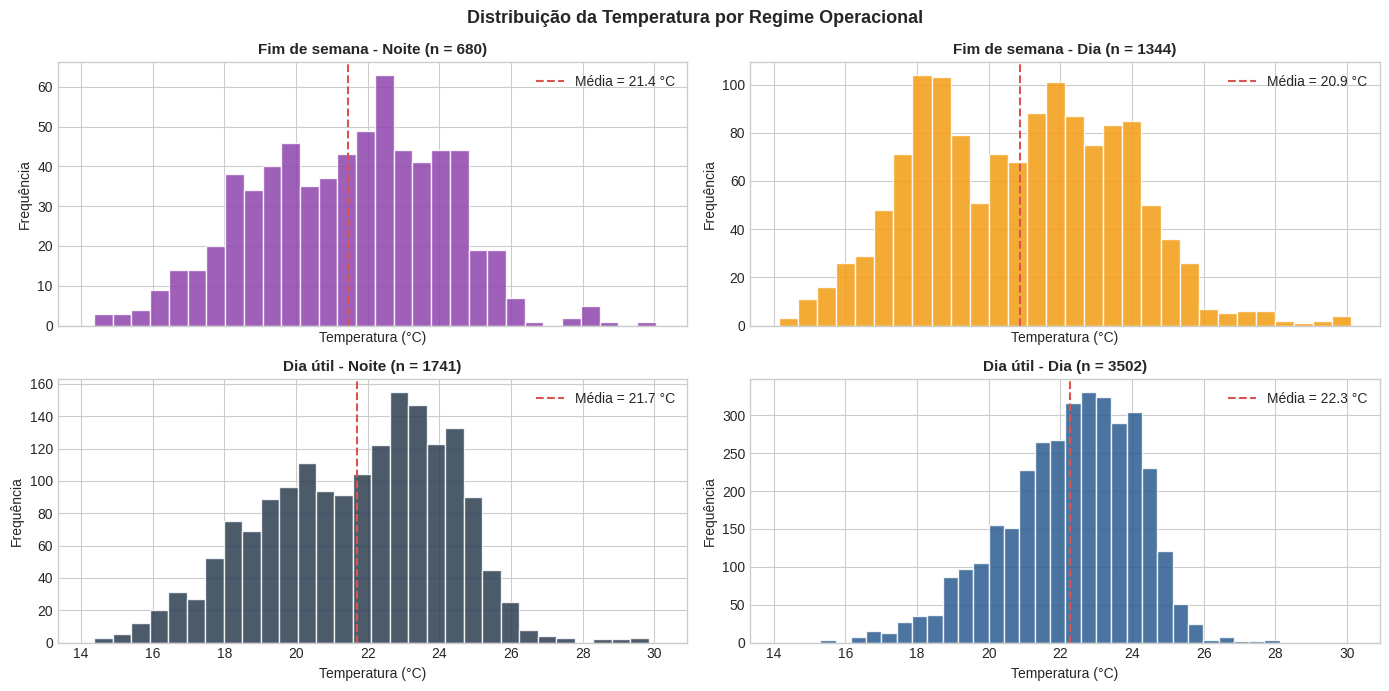

,Nº registros,Média (°C),Desvio padrão,Mínima (°C),Máxima (°C)
categories,,,,,
Fim de semana - Noite,680,21.44,2.63,14.36,30.04
Fim de semana - Dia,1344,20.88,2.80,14.14,30.12
Dia útil - Noite,1741,21.69,2.55,14.37,29.84
Dia útil - Dia,3502,22.28,1.85,15.30,28.13


In [11]:
nomes_categorias = {
    0: 'Fim de semana - Noite',
    1: 'Fim de semana - Dia',
    2: 'Dia útil - Noite',
    3: 'Dia útil - Dia'
}
cores = ['#8e44ad', '#f39c12', '#2c3e50', '#2b5c8f']

# Um histograma para cada categoria, com a média marcada
fig, axs = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for cat, ax in zip(range(4), axs.ravel()):
    temps = df.loc[df['categories'] == cat, 'value']
    ax.hist(temps, bins=30, color=cores[cat], edgecolor='white', alpha=0.85)
    ax.axvline(temps.mean(), color='#d9534f', linestyle='--', linewidth=1.5,
               label=f'Média = {temps.mean():.1f} °C')
    ax.set_title(f'{nomes_categorias[cat]} (n = {len(temps)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Temperatura (°C)')
    ax.set_ylabel('Frequência')
    ax.legend()

plt.suptitle('Distribuição da Temperatura por Regime Operacional', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Tabela resumo por categoria
resumo_categorias = df.groupby('categories')['value'].agg(['count', 'mean', 'std', 'min', 'max']).round(2)
resumo_categorias.index = resumo_categorias.index.map(nomes_categorias)
resumo_categorias.columns = ['Nº registros', 'Média (°C)', 'Desvio padrão', 'Mínima (°C)', 'Máxima (°C)']
resumo_categorias

**Interpretação:** o regime **"Dia útil - Dia"** tem a maior média (22,3 °C) e a menor variação (desvio padrão de 1,85), pois é o período em que a climatização opera de forma controlada. Nos **fins de semana** e à **noite**, a temperatura varia mais (desvio padrão entre 2,5 e 2,8). Isso justifica treinar o Elliptic Envelope separadamente por categoria: uma queda que é normal num fim de semana pode indicar falha num dia útil.

## 3. Modelo 1: Clusterização com K-Means e Redução de Dimensionalidade (PCA)

**Racional Técnico:** Algoritmos baseados em distância pressupõem que observações normais agrupam-se em regiões densas no espaço de atributos, enquanto anomalias permanecem **isoladas longe dos centroides**.

### Pipeline Aplicado:
1. **Padronização (`StandardScaler`):** Transformação para média $0$ e desvio padrão $1$, evitando que escalas diferentes distorçam o cálculo de distância euclidiana.
2. **Redução de Dimensionalidade (`PCA`):** Projeção dos 5 atributos em **2 componentes principais**, mitigando ruído e colinearidade.
3. **Treinamento (`K-Means`):** Primeiro, aplicamos o **método do cotovelo** (inércia × número de clusters). O cotovelo principal aparece em torno de **k = 4**, mas a inércia continua caindo de forma gradual até ~10–15 clusters. Adotamos **15 clusters** (mesmo valor do notebook de referência) porque, para detecção de anomalias, clusters pequenos e compactos representam melhor cada regime de operação, e assim os pontos incomuns ficam mais distantes dos centroides.
4. **Limiar de Decisão (*Threshold*):** Cálculo da distância euclidiana de cada ponto ao centroide mais próximo, rotulando os **1% pontos mais distantes** como anomalias.

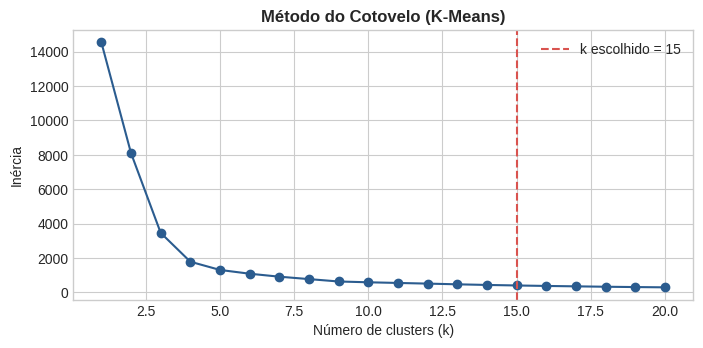

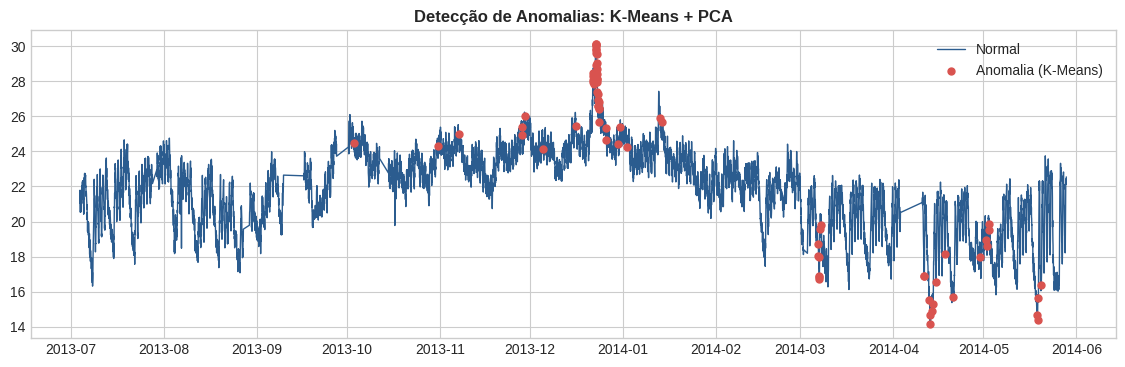

In [3]:
# Seleção e padronização das features
features = ['value', 'hours', 'daylight', 'DayOfTheWeek', 'WeekDay']
scaler = preprocessing.StandardScaler()
data_scaled = scaler.fit_transform(df[features])

# Redução de dimensionalidade para 2 componentes principais
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca = pd.DataFrame(scaler.fit_transform(data_pca), columns=['PC1', 'PC2'])

# Método do cotovelo: inércia para diferentes números de clusters
n_clusters = range(1, 21)
inercias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_pca).inertia_ for k in n_clusters]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(n_clusters, inercias, 'o-', color='#2b5c8f')
ax.axvline(15, color='#d9534f', linestyle='--', label='k escolhido = 15')
ax.set_title("Método do Cotovelo (K-Means)", fontsize=12, fontweight='bold')
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia")
ax.legend()
plt.show()

# Treinamento do K-Means
kmeans = KMeans(n_clusters=15, random_state=42, n_init=10).fit(data_pca)
df['cluster'] = kmeans.labels_

# Distância de cada observação ao centroide do seu próprio cluster
centroides = kmeans.cluster_centers_[kmeans.labels_]
distance = pd.Series(np.linalg.norm(data_pca.values - centroides, axis=1))

# Os 1% pontos mais distantes são marcados como anomalia
threshold_kmeans = distance.nlargest(int(outliers_fraction * len(distance))).min()
df['anomaly_kmeans'] = (distance >= threshold_kmeans).astype(int)

# Visualização dos resultados
fig, ax = plt.subplots(figsize=(14, 4))
anomalies = df[df['anomaly_kmeans'] == 1]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(anomalies['timestamp'], anomalies['value'], color='#d9534f', label='Anomalia (K-Means)', zorder=5, s=25)
ax.set_title("Detecção de Anomalias: K-Means + PCA", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

## 4. Modelo 2: Envelope Elíptico (Distribuição Gaussiana por Regime)

**Racional Técnico:** O `EllipticEnvelope` ajusta uma **distribuição Gaussiana multivariada** aos dados e define uma elipse central que engloba a região de alta densidade (comportamento normal). Pontos projetados fora dessa fronteira estatística são classificados como *outliers*.

* **Estratégia de Segmentação:** Como a temperatura média varia conforme o turno e o dia da semana, aplicar uma única distribuição global mascararia anomalias sutis. Por isso, segmentamos os dados nas **4 categorias operacionais** (`categories`) e treinamos um modelo independente para cada contexto.

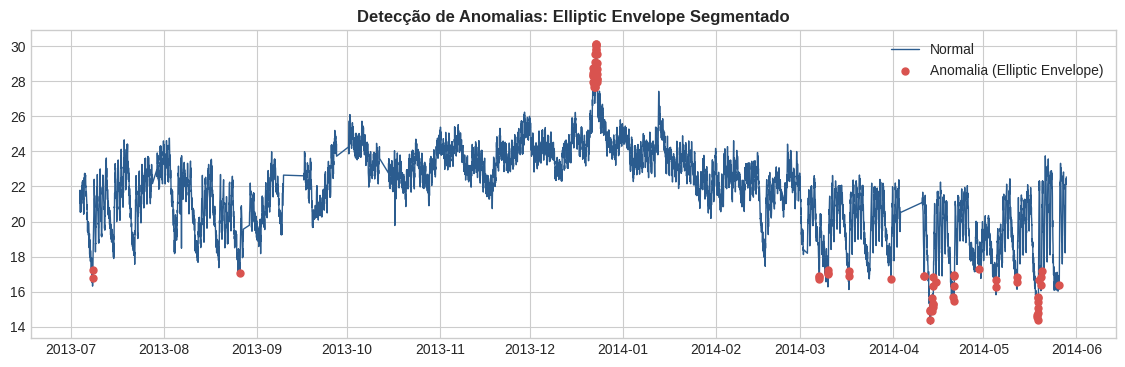

In [4]:
# Coluna começa em 0 (normal) para manter o tipo inteiro
df['anomaly_elliptic'] = 0

# Um modelo independente para cada uma das 4 categorias temporais
for cat in range(4):
    subset = df.loc[df['categories'] == cat, 'value']
    X_train = subset.values.reshape(-1, 1)
    envelope = EllipticEnvelope(contamination=outliers_fraction, random_state=42)
    preds = envelope.fit_predict(X_train)
    df.loc[subset.index, 'anomaly_elliptic'] = (preds == -1).astype(int)

# Visualização dos resultados
fig, ax = plt.subplots(figsize=(14, 4))
anomalies = df[df['anomaly_elliptic'] == 1]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(anomalies['timestamp'], anomalies['value'], color='#d9534f', label='Anomalia (Elliptic Envelope)', zorder=5, s=25)
ax.set_title("Detecção de Anomalias: Elliptic Envelope Segmentado", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

## 5. Modelo 3: Isolation Forest

**Racional Técnico:** Diferente de métodos baseados em distância ou densidade, o **Isolation Forest** isola observações selecionando aleatoriamente um atributo e um ponto de corte entre seus valores mínimo e máximo.

* **Princípio de Isolamento:** Como anomalias possuem valores extremos ou combinações raras de atributos, elas exigem **menos divisões (caminhos mais curtos nas árvores)** para serem isoladas do restante dos dados. Isso o torna altamente eficiente e escalável sem exigir premissas sobre a distribuição estatística da série.

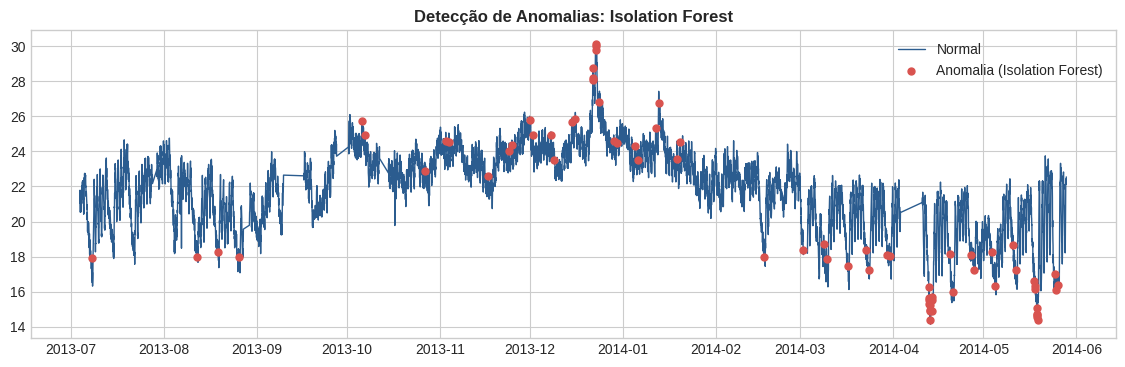

In [5]:
data_scaled = scaler.fit_transform(df[features])

# Treinamento do Isolation Forest
model_if = IsolationForest(contamination=outliers_fraction, random_state=42)
model_if.fit(data_scaled)

# Mapeamento: -1 (anomalia) -> 1 | 1 (normal) -> 0
df['anomaly_iforest'] = pd.Series(model_if.predict(data_scaled)).map({1: 0, -1: 1})

# Visualização dos resultados
fig, ax = plt.subplots(figsize=(14, 4))
anomalies = df[df['anomaly_iforest'] == 1]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(anomalies['timestamp'], anomalies['value'], color='#d9534f', label='Anomalia (Isolation Forest)', zorder=5, s=25)
ax.set_title("Detecção de Anomalias: Isolation Forest", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

## 6. Modelo 4: One-Class SVM

**Racional Técnico:** O **One-Class Support Vector Machine** aprende uma função de fronteira não linear (utilizando o *kernel* **RBF** — *Radial Basis Function*) que envolve a região onde se concentra a maioria das observações normais.

* **Critério de Classificação:** Qualquer ponto projetado fora dessa fronteira aprendida é classificado como anomalia. O hiperparâmetro `nu` atua como um limite superior para a fração de anomalias esperadas no conjunto de treinamento.
* **Escolha do `gamma = 0.01`:** o `gamma` controla o alcance de influência de cada ponto no kernel RBF. Um valor **baixo** gera uma fronteira **mais suave**, que acompanha a forma geral dos dados sem se ajustar ao ruído de cada leitura. Valores altos tendem a "recortar" a fronteira em volta de pontos isolados (sobreajuste).

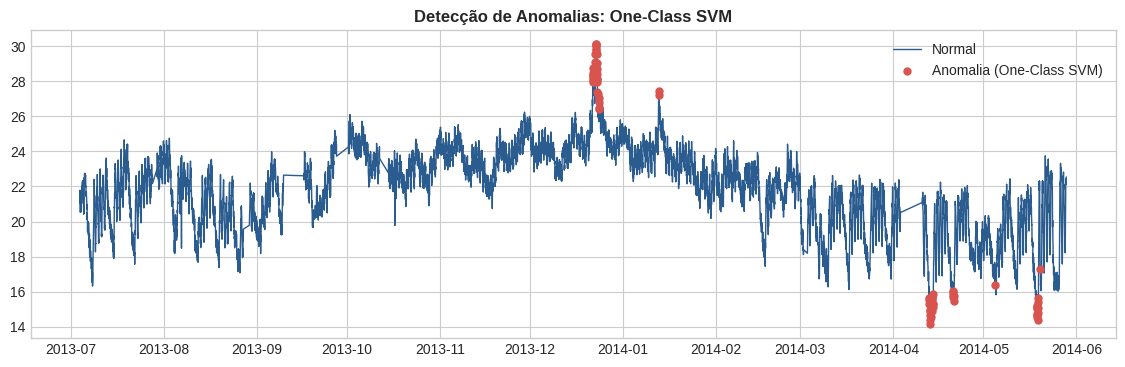

In [6]:
# Treinamento do One-Class SVM com kernel RBF
model_svm = OneClassSVM(nu=outliers_fraction, kernel="rbf", gamma=0.01)
model_svm.fit(data_scaled)

# Mapeamento das predições
df['anomaly_svm'] = pd.Series(model_svm.predict(data_scaled)).map({1: 0, -1: 1})

# Visualização dos resultados
fig, ax = plt.subplots(figsize=(14, 4))
anomalies = df[df['anomaly_svm'] == 1]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(anomalies['timestamp'], anomalies['value'], color='#d9534f', label='Anomalia (One-Class SVM)', zorder=5, s=25)
ax.set_title("Detecção de Anomalias: One-Class SVM", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

## 7. Modelo 5: Previsão Sequencial com LSTM (*Long Short-Term Memory*)

**Racional Técnico:** Enquanto os modelos anteriores avaliam registros de forma pontual, redes neurais recorrentes do tipo **LSTM** capturam **dependências sequenciais e padrões temporais** ao longo do tempo.

### Lógica de Detecção via Erro Residual:
1. **Janelas Deslizantes:** Organização da série em sequências de **50 passos temporais** (`unroll_length = 50`).
2. **Previsão Temporal:** A rede é treinada para prever o valor da temperatura no instante $t+1$ com base nos 50 instantes anteriores.
3. **Cálculo do Erro Absoluto:** Medimos a diferença entre o valor real e o valor previsto pela rede. Quando ocorre uma falha abrupta no sistema, o comportamento foge da dinâmica aprendida, gerando **picos elevados no erro de previsão**.

> **Observação importante:** a rede é treinada nos primeiros 80% da série e avaliada em toda ela. No trecho final (os 20% de teste), os dados nunca foram vistos pelo modelo, então o erro de previsão tende a ser naturalmente maior. Por isso, as anomalias da LSTM se **concentram no fim da série**. Isso deve ser levado em conta na comparação com os demais métodos. Fixamos uma semente aleatória para tornar o resultado mais reprodutível.

Epoch 1/5
82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - loss: 0.1132 - val_loss: 0.0796
Epoch 2/5
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - loss: 0.0459 - val_loss: 0.0642
Epoch 3/5
82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 121ms/step - loss: 0.0421 - val_loss: 0.0588
Epoch 4/5
82/82 ━━━━━━━━━━━━━━━━━━━━ 12s 150ms/step - loss: 0.0394 - val_loss: 0.0551
Epoch 5/5
82/82 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - loss: 0.0373 - val_loss: 0.0522


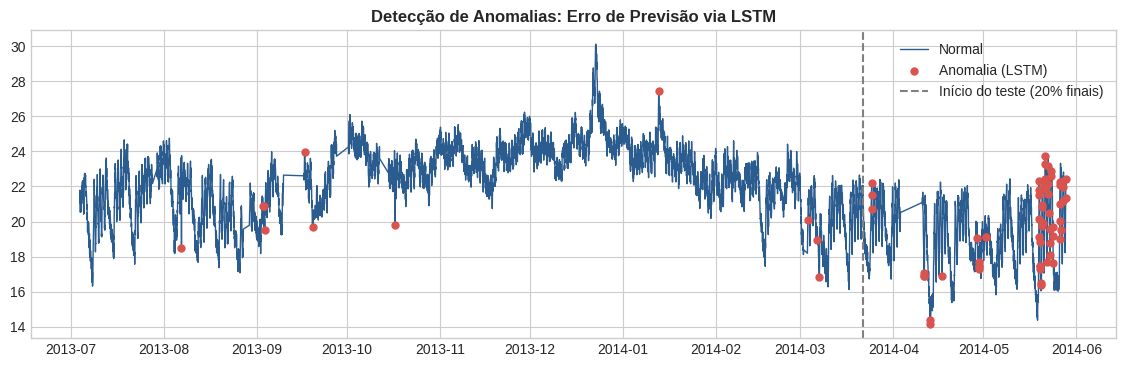

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Input

# Semente fixa para tornar o treinamento mais reprodutível
tf.keras.utils.set_random_seed(42)

data_n = scaler.fit_transform(df[features])

# Criação das sequências temporais (janelas de 50 observações)
unroll_length = 50
X_seq, y_seq = [], []
for i in range(len(data_n) - unroll_length):
    X_seq.append(data_n[i:i + unroll_length])
    y_seq.append(data_n[i + unroll_length, 0])

X_seq, y_seq = np.array(X_seq), np.array(y_seq)

# Divisão treino/teste (80% / 20%) respeitando a ordem temporal
test_size = int(len(X_seq) * 0.2)
X_train, X_test = X_seq[:-test_size], X_seq[-test_size:]
y_train, y_test = y_seq[:-test_size], y_seq[-test_size:]

# Arquitetura da Rede LSTM
model_lstm = Sequential([
    Input(shape=(unroll_length, X_seq.shape[2])),
    LSTM(64, return_sequences=True),
    LSTM(32, return_sequences=False),
    Dense(1)
])
model_lstm.compile(loss='mse', optimizer='adam')
model_lstm.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=1)

# Cálculo do erro absoluto de previsão
preds = model_lstm.predict(X_seq, verbose=0).flatten()
errors = np.abs(y_seq - preds)

# Definição do limiar para o top 1% maiores erros
threshold_lstm = pd.Series(errors).nlargest(int(outliers_fraction * len(errors))).min()
anomalies_lstm = (errors >= threshold_lstm).astype(int)

df['anomaly_lstm'] = 0
df.iloc[unroll_length:, df.columns.get_loc('anomaly_lstm')] = anomalies_lstm

# Visualização dos resultados (linha tracejada = início do trecho de teste)
inicio_teste = df['timestamp'].iloc[unroll_length + len(X_train)]
fig, ax = plt.subplots(figsize=(14, 4))
anomalies = df[df['anomaly_lstm'] == 1]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(anomalies['timestamp'], anomalies['value'], color='#d9534f', label='Anomalia (LSTM)', zorder=5, s=25)
ax.axvline(inicio_teste, color='gray', linestyle='--', label='Início do teste (20% finais)')
ax.set_title("Detecção de Anomalias: Erro de Previsão via LSTM", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

## 8. Análise Comparativa e Consenso dos Algoritmos

Em cenários não supervisionados (onde não há rótulos prévios durante o treinamento), combinar múltiplos paradigmas permite identificar **anomalias de alto consenso** — instantes em que algoritmos baseados em distância, densidade, árvores e redes neurais convergem simultaneamente.

Abaixo consolidamos o **total de alertas gerados por cada modelo** e isolamos os eventos onde houve concordância de **pelo menos 3 algoritmos**.

Na sequência, um painel resume visualmente a comparação (8.1) e, na seção 9, verificamos esses alertas contra as falhas reais registradas no NAB.

Total de anomalias detectadas por algoritmo:

K-Means + PCA           72
Elliptic Envelope       75
Isolation Forest        73
One-Class SVM           74
LSTM (Erro Previsão)    72
dtype: int64


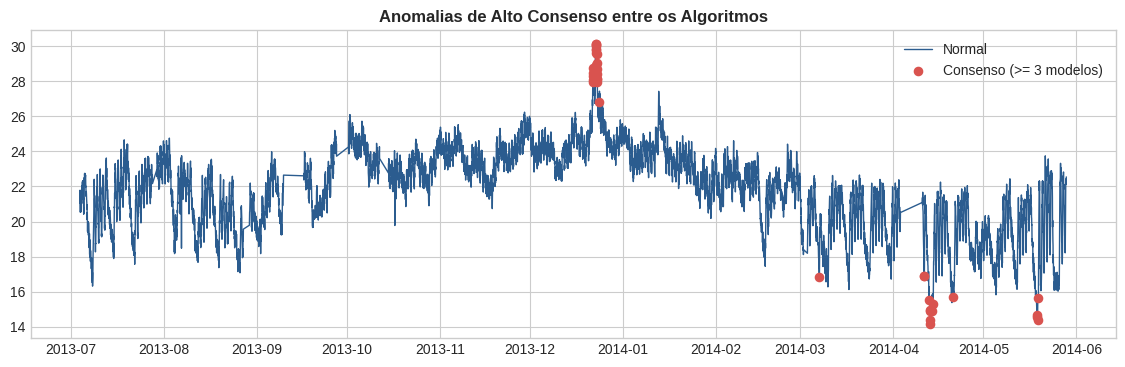

In [8]:
cols_anomalias = ['anomaly_kmeans', 'anomaly_elliptic', 'anomaly_iforest', 'anomaly_svm', 'anomaly_lstm']

# Contagem de anomalias por modelo
resumo = df[cols_anomalias].sum().rename({
    'anomaly_kmeans': 'K-Means + PCA',
    'anomaly_elliptic': 'Elliptic Envelope',
    'anomaly_iforest': 'Isolation Forest',
    'anomaly_svm': 'One-Class SVM',
    'anomaly_lstm': 'LSTM (Erro Previsão)'
})
print("Total de anomalias detectadas por algoritmo:\n")
print(resumo)

# Score de consenso (quantos modelos apontaram anomalia no mesmo instante)
df['consenso_modelos'] = df[cols_anomalias].sum(axis=1)

# Plotando anomalias com alto consenso (>= 3 modelos concordando)
fig, ax = plt.subplots(figsize=(14, 4))
alto_consenso = df[df['consenso_modelos'] >= 3]
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', label='Normal', linewidth=1)
ax.scatter(alto_consenso['timestamp'], alto_consenso['value'], color='#d9534f', label='Consenso (>= 3 modelos)', zorder=5, s=35)
ax.set_title("Anomalias de Alto Consenso entre os Algoritmos", fontsize=12, fontweight='bold')
ax.legend()
plt.show()

### 8.1 Painel Comparativo

O painel abaixo resume os resultados em três visões:
1. **Quantidade de alertas por modelo.** Todos ficam próximos de 1%, como definido em `outliers_fraction`.
2. **Faixa de temperatura dos alertas.** Mostra se cada modelo marca extremos globais (muito quente/muito frio) ou valores intermediários que são incomuns apenas para o contexto.
3. **Mapa de consenso ao longo do tempo.** Alertas isolados (1 a 2 modelos) em laranja e consenso forte (≥ 3 modelos) em vermelho.

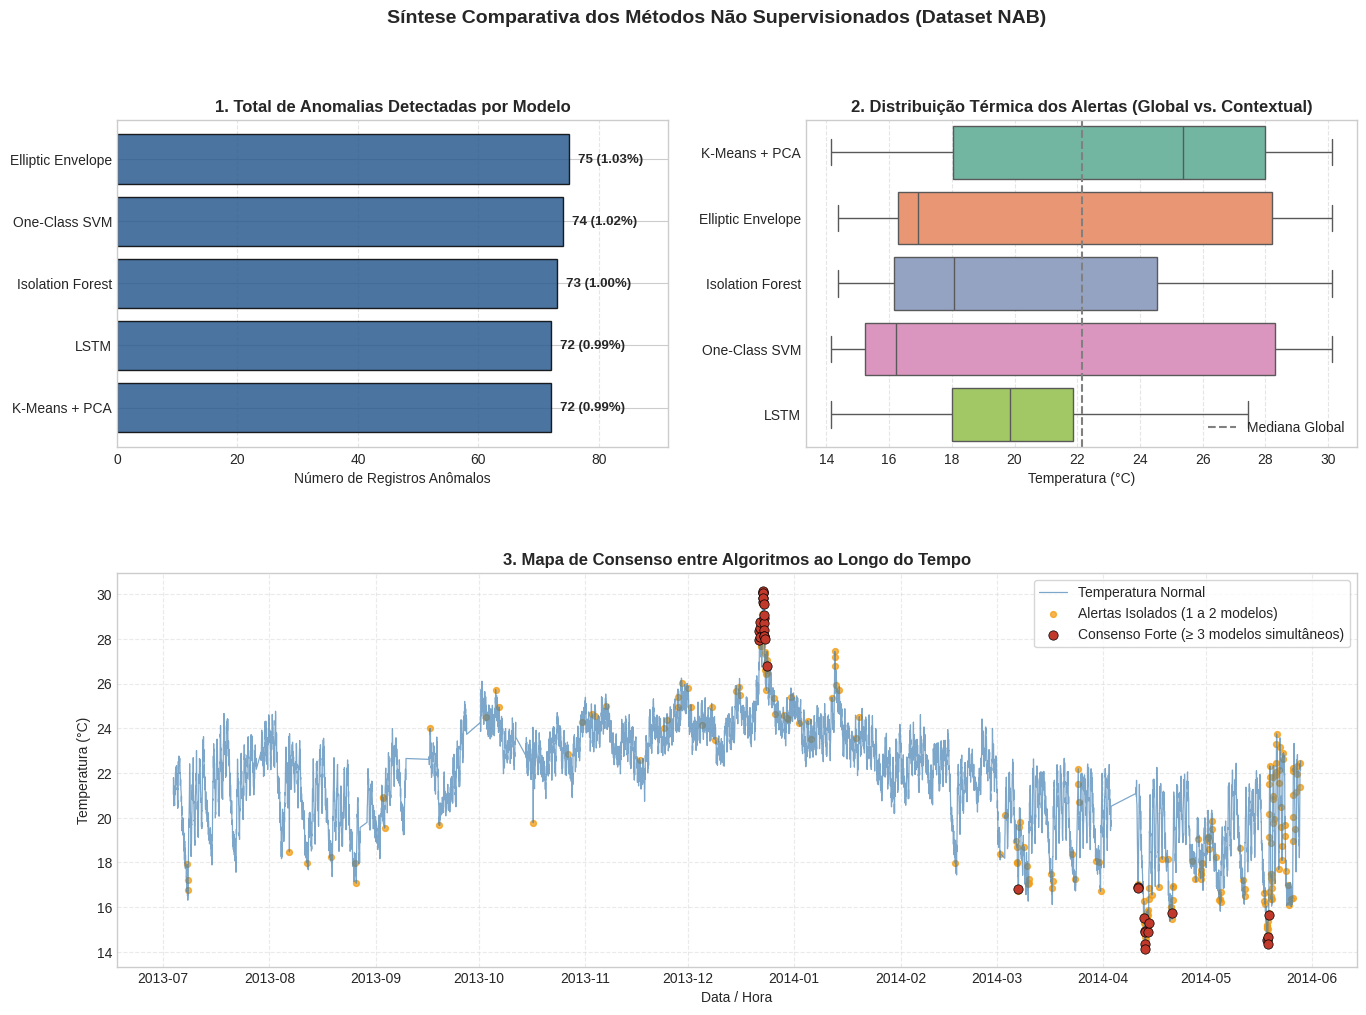

In [9]:
mapa_modelos = {
    'K-Means + PCA': 'anomaly_kmeans',
    'Elliptic Envelope': 'anomaly_elliptic',
    'Isolation Forest': 'anomaly_iforest',
    'One-Class SVM': 'anomaly_svm',
    'LSTM': 'anomaly_lstm'
}
nomes_cols = list(mapa_modelos.keys())

# Tabela resumo com nomes amigáveis (todas as colunas já estão em 1 = anomalia, 0 = normal)
df_resumo = df[['timestamp', 'value']].copy()
for nome_exibicao, col in mapa_modelos.items():
    df_resumo[nome_exibicao] = df[col]
df_resumo['Consenso'] = df['consenso_modelos']

fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], hspace=0.35, wspace=0.25)

# --- GRÁFICO 1: Contagem de Anomalias por Algoritmo (Barras Horizontais) ---
ax1 = fig.add_subplot(gs[0, 0])
contagens = df_resumo[nomes_cols].sum().sort_values(ascending=True)
percentuais = (contagens / len(df_resumo)) * 100

bars = ax1.barh(contagens.index, contagens.values, color='#2b5c8f', edgecolor='black', alpha=0.85)
ax1.set_title('1. Total de Anomalias Detectadas por Modelo', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número de Registros Anômalos')
ax1.grid(axis='x', linestyle='--', alpha=0.5)
ax1.set_xlim(0, contagens.max() * 1.22)

for bar, pct in zip(bars, percentuais):
    largura = bar.get_width()
    ax1.text(largura + (contagens.max() * 0.02), bar.get_y() + bar.get_height()/2,
             f'{int(largura)} ({pct:.2f}%)', va='center', fontsize=9.5, fontweight='bold')

# --- GRÁFICO 2: Faixa de Temperatura das Anomalias (Boxplot) ---
ax2 = fig.add_subplot(gs[0, 1])
df_box = pd.concat([
    pd.DataFrame({'Modelo': nome, 'Temperatura (°C)': df_resumo.loc[df_resumo[nome] == 1, 'value']})
    for nome in nomes_cols
])
sns.boxplot(data=df_box, x='Temperatura (°C)', y='Modelo', hue='Modelo',
            ax=ax2, palette='Set2', fliersize=3, legend=False)
ax2.axvline(df_resumo['value'].median(), color='gray', linestyle='--', label='Mediana Global')
ax2.set_title('2. Distribuição Térmica dos Alertas (Global vs. Contextual)', fontsize=12, fontweight='bold')
ax2.set_ylabel('')
ax2.legend(loc='lower right')
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# --- GRÁFICO 3: Série Temporal por Grau de Consenso ---
ax3 = fig.add_subplot(gs[1, :])
ax3.plot(df_resumo['timestamp'], df_resumo['value'], color='steelblue', linewidth=0.9, alpha=0.7, label='Temperatura Normal')

baixa_conc = df_resumo[(df_resumo['Consenso'] >= 1) & (df_resumo['Consenso'] < 3)]
ax3.scatter(baixa_conc['timestamp'], baixa_conc['value'], color='#f39c12', s=18, alpha=0.75,
            label='Alertas Isolados (1 a 2 modelos)')

alta_conc = df_resumo[df_resumo['Consenso'] >= 3]
ax3.scatter(alta_conc['timestamp'], alta_conc['value'], color='#c0392b', s=45, zorder=5, edgecolor='black', linewidth=0.5,
            label='Consenso Forte (≥ 3 modelos simultâneos)')

ax3.set_title('3. Mapa de Consenso entre Algoritmos ao Longo do Tempo', fontsize=12, fontweight='bold')
ax3.set_xlabel('Data / Hora')
ax3.set_ylabel('Temperatura (°C)')
ax3.legend(loc='upper right', frameon=True)
ax3.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Síntese Comparativa dos Métodos Não Supervisionados (Dataset NAB)', fontsize=14, fontweight='bold', y=0.98)
plt.show()

## 9. Validação com as Janelas de Falha do NAB

Como o aprendizado é **não supervisionado**, nenhum modelo viu rótulos durante o treinamento. Mesmo assim, o NAB publica as janelas de tempo em que a falha real ocorreu (`labels/combined_windows.json`). Para esta série são duas:

| Janela | Início | Fim | Evento |
|---|---|---|---|
| 1 | 15/12/2013 07:00 | 30/12/2013 09:00 | pico de temperatura (falha na climatização) |
| 2 | 29/03/2014 15:00 | 20/04/2014 22:00 | quedas bruscas de temperatura |

Usamos essas janelas **apenas como gabarito**, para medir:
* **% de alertas dentro das janelas** (uma espécie de precisão). Como referência, um detector aleatório acertaria a mesma proporção de pontos que as janelas ocupam na série.
* **Janelas atingidas:** quantas das 2 falhas receberam ao menos um alerta.

Referência (detector aleatório): 10.0% dos pontos da série estão dentro das janelas.

                        Nº alertas  % dentro das janelas Janelas atingidas
Modelo                                                                    
K-Means + PCA                   72                  59.7               2/2
Elliptic Envelope               75                  54.7               2/2
Isolation Forest                73                  34.2               2/2
One-Class SVM                   74                  71.6               2/2
LSTM                            72                   8.3               1/2
Consenso (≥ 3 modelos)          36                  83.3               2/2


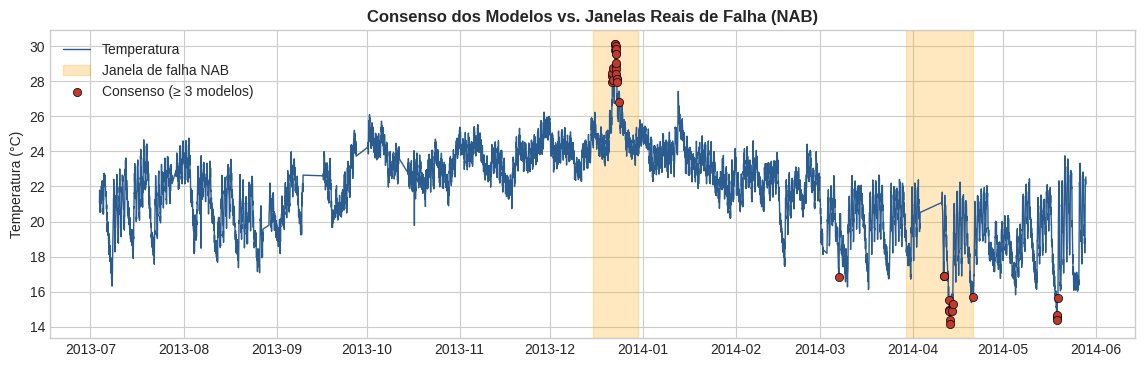

In [10]:
janelas_nab = [('2013-12-15 07:00', '2013-12-30 09:00'),
               ('2014-03-29 15:00', '2014-04-20 22:00')]

def dentro_janelas(janelas):
    mascara = np.zeros(len(df), dtype=bool)
    for ini, fim in janelas:
        mascara |= ((df['timestamp'] >= ini) & (df['timestamp'] <= fim)).values
    return mascara

na_janela = dentro_janelas(janelas_nab)
print(f"Referência (detector aleatório): {100 * na_janela.mean():.1f}% dos pontos da série estão dentro das janelas.\n")

# Cada modelo individual + o consenso (>= 3 modelos)
deteccoes = {nome: df[col] == 1 for nome, col in mapa_modelos.items()}
deteccoes['Consenso (≥ 3 modelos)'] = df['consenso_modelos'] >= 3

linhas = []
for nome, det in deteccoes.items():
    det = det.values
    atingidas = sum(det[dentro_janelas([j])].any() for j in janelas_nab)
    linhas.append({'Modelo': nome,
                   'Nº alertas': int(det.sum()),
                   '% dentro das janelas': round(100 * (det & na_janela).sum() / max(det.sum(), 1), 1),
                   'Janelas atingidas': f'{atingidas}/{len(janelas_nab)}'})
tabela_validacao = pd.DataFrame(linhas).set_index('Modelo')
print(tabela_validacao)

# Gráfico: consenso forte com as janelas de falha sombreadas
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df['timestamp'], df['value'], color='#2b5c8f', linewidth=1, label='Temperatura')
for i, (ini, fim) in enumerate(janelas_nab):
    ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color='orange', alpha=0.25,
               label='Janela de falha NAB' if i == 0 else None)
cons = df[df['consenso_modelos'] >= 3]
ax.scatter(cons['timestamp'], cons['value'], color='#c0392b', s=35, zorder=5, edgecolor='black', linewidth=0.5,
           label='Consenso (≥ 3 modelos)')
ax.set_title("Consenso dos Modelos vs. Janelas Reais de Falha (NAB)", fontsize=12, fontweight='bold')
ax.set_ylabel("Temperatura (°C)")
ax.legend()
plt.show()

## 10. Conclusões

* **Importância do contexto temporal:** a temperatura "normal" depende do horário e do dia da semana. Modelos que usam essas informações (Elliptic Envelope segmentado por regime e os modelos com atributos de hora/dia) conseguem marcar valores que só são estranhos **naquele contexto**, e não apenas os extremos absolutos. O boxplot do painel mostra isso: parte dos alertas está em temperaturas intermediárias.
* **Anomalias pontuais vs. sequenciais:** K-Means, Elliptic Envelope, Isolation Forest e One-Class SVM detectam principalmente **valores extremos**: o pico de calor no fim de dezembro e as quedas de temperatura em abril. A LSTM procura **rupturas na dinâmica** da série, mas neste experimento **não detectou o pico de dezembro** e concentrou seus alertas no trecho final, que não foi usado no treino. Isso indica que o erro de previsão cresce em dados novos, e não necessariamente que há falha. Com mais épocas de treino e um esquema de validação contínua, o resultado poderia melhorar.
* **Validação com o NAB:** a tabela da seção 9 mostra que K-Means, Elliptic Envelope, Isolation Forest e One-Class SVM concentram seus alertas dentro das janelas reais de falha bem acima do que um detector aleatório faria (10%), e todos atingem as duas falhas. A LSTM é a exceção: ficou próxima do acaso e atingiu apenas uma das falhas, confirmando que, com este treinamento, ela reage mais a dados novos do que a falhas reais. O consenso entre modelos foi a estratégia mais precisa.
* **Estratégia de *ensemble* (consenso):** exigir que ≥ 3 modelos concordem reduz os alertas isolados de cada técnica e destaca os dois eventos de falha. O consenso, porém, **não é perfeito**: ainda aparecem alguns alertas fora das janelas (por exemplo, quedas de temperatura em maio). Num cenário real, esses alertas exigiriam verificação por um especialista.
* **Limitações:** o parâmetro `outliers_fraction = 0.01` foi fixado por suposição e controla diretamente o equilíbrio entre falsos alarmes e falhas perdidas. Os hiperparâmetros (nº de clusters, `gamma`, arquitetura da LSTM) também foram escolhidos de forma heurística, já que, sem rótulos, não há como otimizá-los diretamente.